In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install ultralytics
!pip install opencv-python
!pip install matplotlib

In [ ]:
import os
Datasets =os.path.join('drive','MyDrive','datasets')
print(Datasets)

drive/MyDrive/datasets


In [ ]:
for item in os.listdir(Datasets):
  print(item)

Newspaper-Ads-Detection-6


In [ ]:
Dataset = os.path.join(Datasets,'Newspaper-Ads-Detection-6')
print(Dataset)

drive/MyDrive/datasets/Newspaper-Ads-Detection-6


In [ ]:
for item in os.listdir(Dataset):
  print(item)

README.dataset.txt
README.roboflow.txt
data.yaml
train


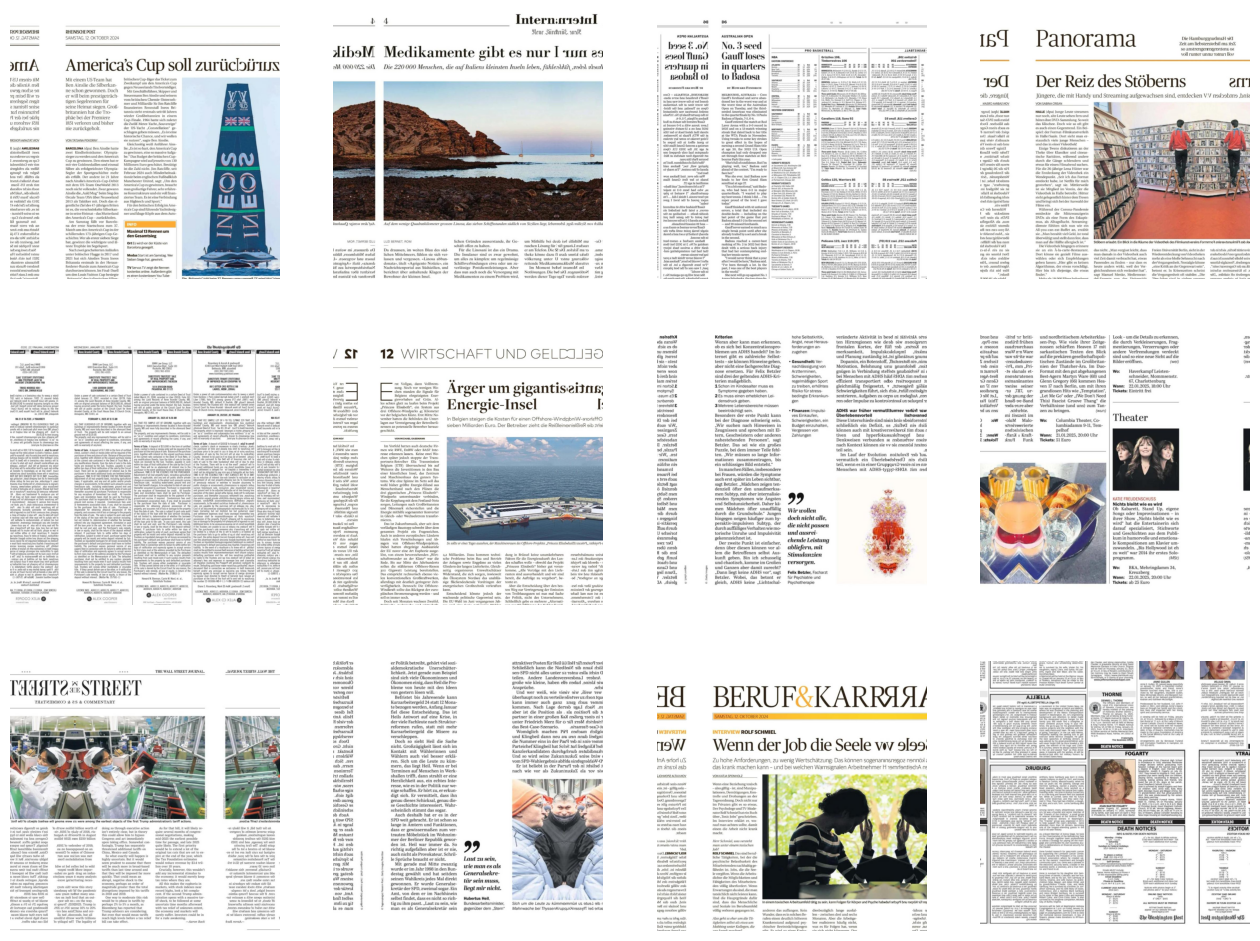

In [ ]:
train_data=os.path.join(Dataset,'train')
for item in os.listdir(train_data):
  print(item)

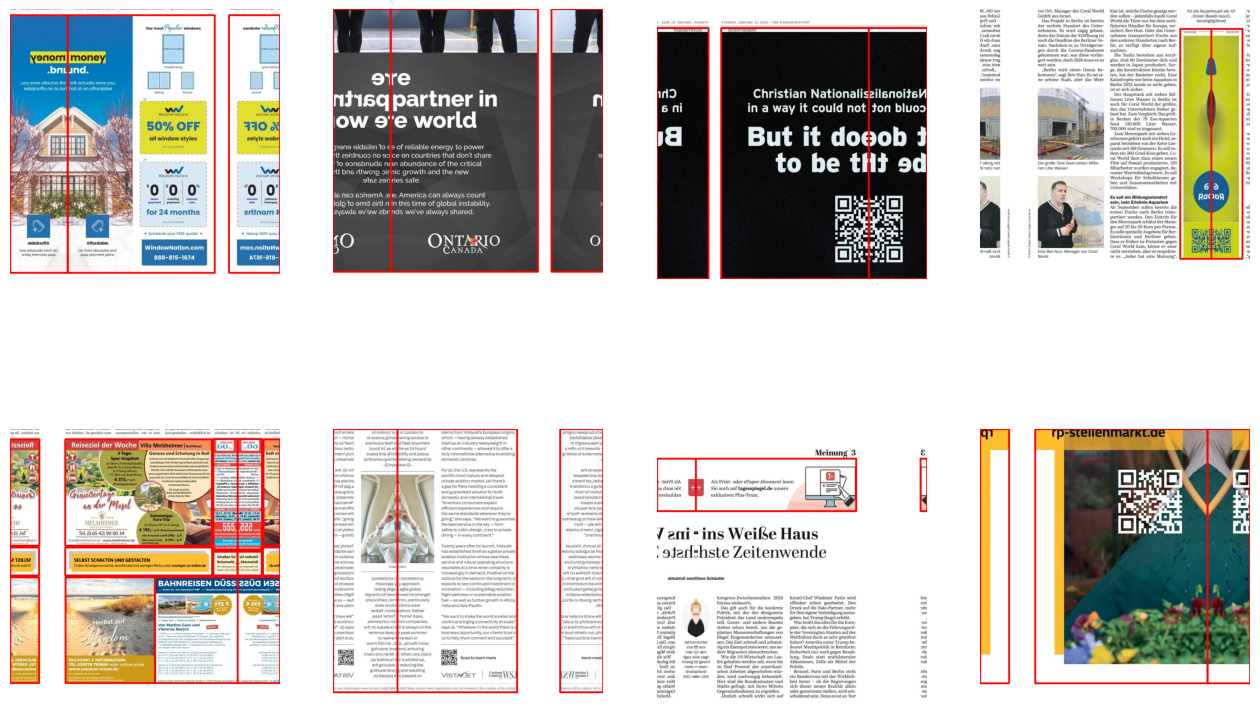

In [ ]:
imgs = os.path.join(train_data,'images')
len(os.listdir(imgs))

In [ ]:
image_files = []
for item in os.listdir(imgs):
    if item.lower().endswith(('.jpg', '.jpeg', '.png')):
        image_files.append(item)
print('images:', len(image_files))
print('label files:', len(os.listdir(labels)))


images: 1072
label files: 1072


In [ ]:
#lets check the newspaper that are having no ads only news
empty = 0          # pages with no ad
class_count = {}   # how many boxes per class id
bad_rows = 0       # rows that are not "class x y w h"

for item in image_files:
    name = os.path.splitext(item)[0]
    label_path = os.path.join(labels, name + '.txt')
    rows = []
    if os.path.exists(label_path):
        for line in open(label_path).read().splitlines():
            if line.strip() != '':
                rows.append(line.split())
    if len(rows) == 0:
        empty += 1
    for row in rows:
        class_count[row[0]] = class_count.get(row[0], 0) + 1
        if len(row) != 5:
            bad_rows += 1

print('pages with no ads:', empty, 'out of', len(image_files))
print('boxes per class id:', class_count)
print('bad rows (not 5 numbers):', bad_rows)

pages with no ads: 384 out of 1072
boxes per class id: {'0': 2542}
bad rows (not 5 numbers): 0


empty pages: 384


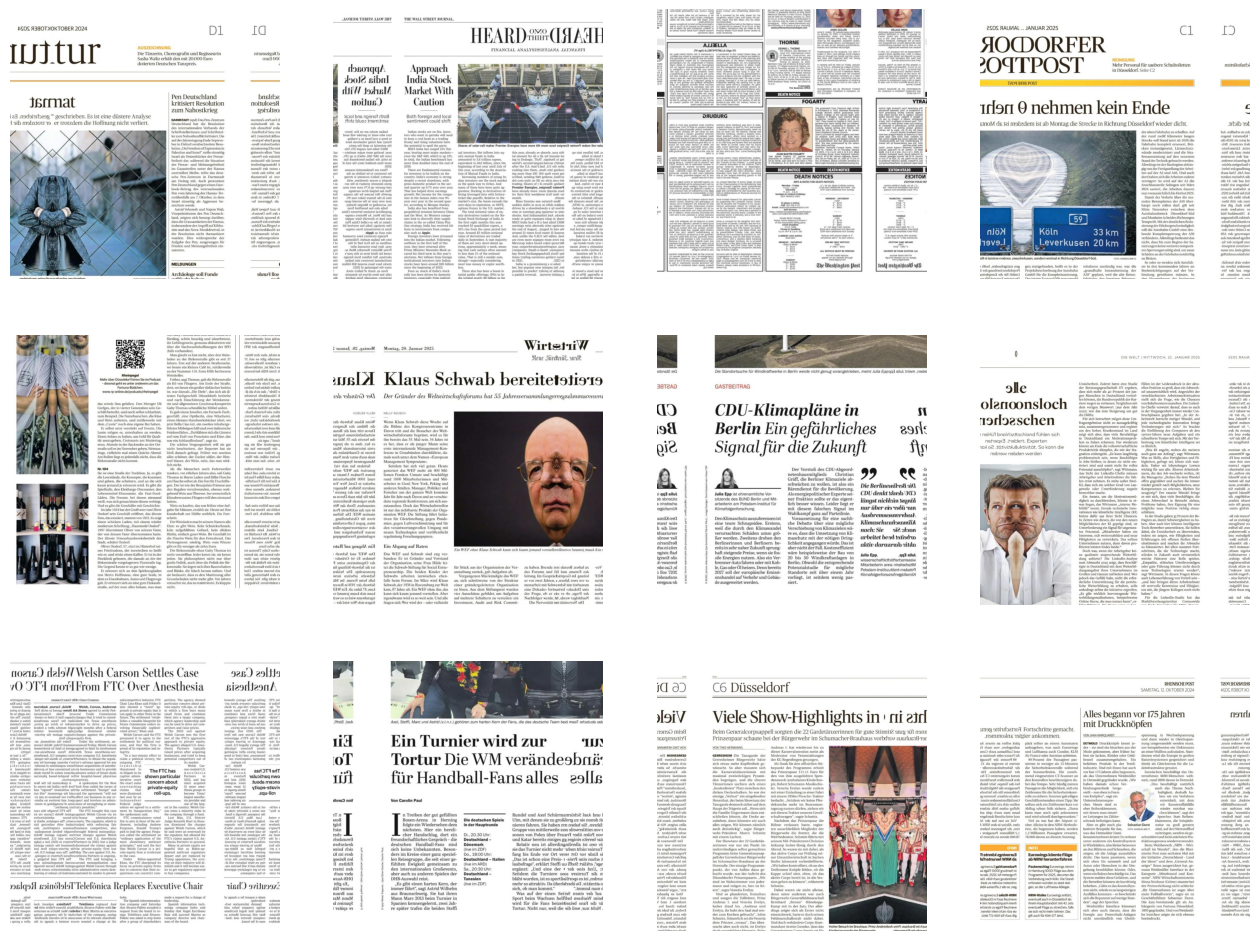

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

empty_files = []
for item in image_files:
    name = os.path.splitext(item)[0]
    label_path = os.path.join(labels, name + '.txt')
    if (not os.path.exists(label_path)) or open(label_path).read().strip() == '':
        empty_files.append(item)

print('empty pages:', len(empty_files))
random.seed(1)
sample = random.sample(empty_files, 12)

plt.figure(figsize=(16, 12))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(mpimg.imread(os.path.join(imgs, sample[i])))
    plt.axis('off')
plt.show()

In [ ]:
import cv2

def to_square_reflect(img, size=1024):
    h, w = img.shape[:2]
    s = size / max(h, w)
    nw, nh = round(w * s), round(h * s)
    small = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
    left = (size - nw) // 2; top = (size - nh) // 2          # ASSUMES centred padding: verify below
    sq = cv2.copyMakeBorder(small, top, size - nh - top, left, size - nw - left, cv2.BORDER_REFLECT)
    return sq, s, left, top

def box_back(box, s, left, top, w, h):                          # box = x1, y1, x2, y2 in the square
    x1, y1, x2, y2 = box
    x1, x2 = (x1 - left) / s, (x2 - left) / s
    y1, y2 = (y1 - top) / s, (y2 - top) / s
    return max(0, round(x1)), max(0, round(y1)), min(w, round(x2)), min(h, round(y2))

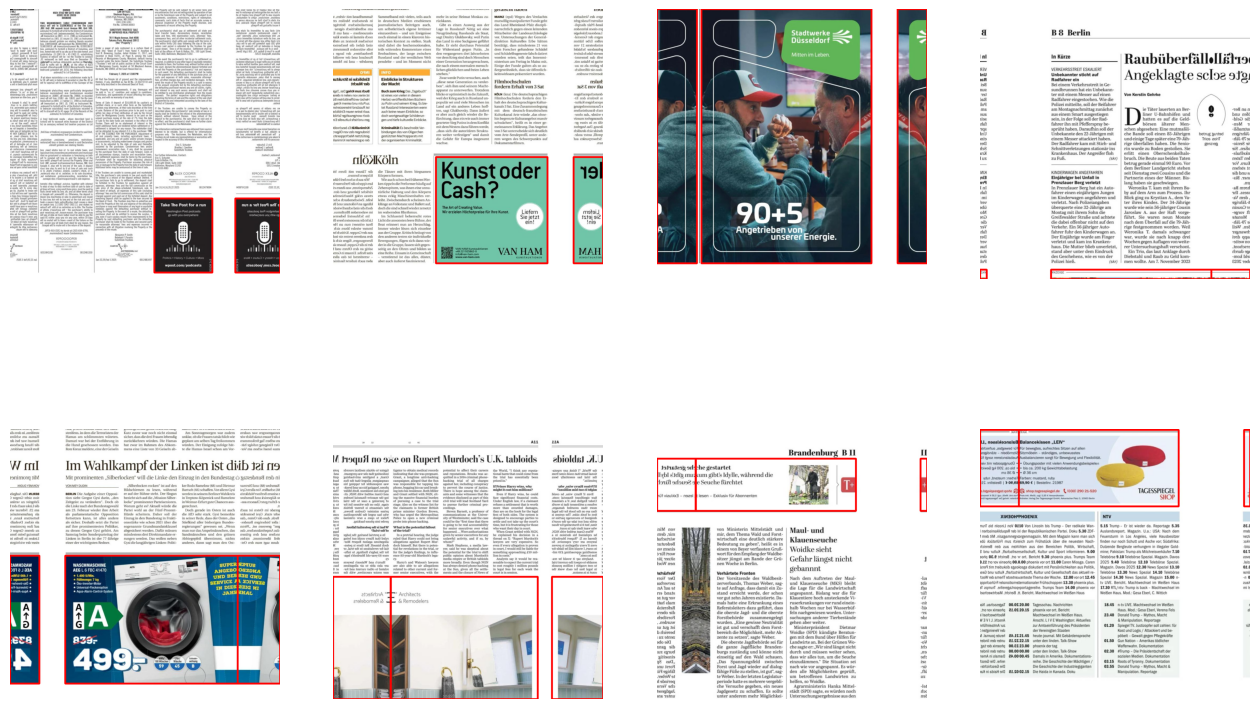

In [ ]:
import cv2

pos_files = []
for item in image_files:
    name = os.path.splitext(item)[0]
    label_path = os.path.join(labels, name + '.txt')
    if os.path.exists(label_path) and open(label_path).read().strip() != '':
        pos_files.append(item)

random.seed(2)
sample = random.sample(pos_files, 8)

plt.figure(figsize=(16, 10))
for i in range(8):
    img = cv2.cvtColor(cv2.imread(os.path.join(imgs, sample[i])), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    name = os.path.splitext(sample[i])[0]
    for line in open(os.path.join(labels, name + '.txt')).read().splitlines():
        c, x, y, bw, bh = line.split()
        x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
        cv2.rectangle(img, (int(x - bw / 2), int(y - bh / 2)), (int(x + bw / 2), int(y + bh / 2)), (255, 0, 0), max(3, w // 150))
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.axis('off')
plt.show()